      HR Analytics: Employee Attrition Analysis Using Python

>





# Table of Contents

1. **Introduction**
   - Project Objectives

2. **Data Loading, Cleaning and Preprocessing**
   - 2.1 Data Loading and Initial Inspection
   - 2.2 Statistical Summary
   - 2.3 Data Cleaning
   - 2.4 Handling Missing Values
   - 2.5 Removing Duplicate Records
   - 2.6 Final Dataset Verification

3. **Exploratory Data Analysis (EDA)**
   - 3.1 Statistical Summary
   - 3.2 Employee Attrition Analysis
   - 3.3 Department-wise Attrition Analysis
   - 3.4 Gender-wise Attrition Analysis
   - 3.5 Age Group-wise Attrition Analysis
   - 3.6 Salary-wise Attrition Analysis
   - 3.7 Attrition Based on Years at Company
   - 3.8 Job Role-wise Attrition Analysis
   - 3.9 Job Satisfaction and Employee Attrition
   - 3.10 Environment Satisfaction and Employee Attrition
   - 3.11 Work-Life Balance and Employee Attrition

4. **Correlation Analysis**
   - 4.1 Preparing Variables for Correlation Analysis
   - 4.2 Correlation Heatmap
   - 4.3 Key Observations
   - 4.4 Variables Most Associated with Employee Attrition
   - 4.5 Interpretation of Correlation Results

5. **Statistical Hypothesis Testing**
   - 5.1 Chi-Square Test of Independence – Department and Attrition
   - 5.2 Interpretation of Chi-Square Test
   - 5.3 Measuring Association Strength Using Cramér's V
   - 5.4 Overtime and Employee Attrition
   - 5.4.1 Effect Size Analysis – Overtime and Attrition
   - 5.5 Job Satisfaction and Employee Attrition
   - 5.6 Environment Satisfaction and Employee Attrition
   - 5.7 Work-Life Balance and Employee Attrition
   - 5.8 Comparative Analysis of Chi-Square Tests

6. **Logistic Regression Analysis**
   - 6.1 Introduction
   - 6.2 Data Preparation
   - 6.3 Identifying Categorical and Numerical Features
   - 6.4 Data Preprocessing
   - 6.5 Train-Test Split
   - 6.6 Building and Training the Logistic Regression Model
   - 6.7 Model Evaluation
   - 6.8 Confusion Matrix
   - 6.9 ROC Curve Analysis
   - 6.10 Feature Importance and Coefficient Analysis

7. **Business Insights and Recommendations**
   - Insight 1: Overtime and Employee Attrition
   - Insight 2: Job Satisfaction and Employee Attrition
   - Insight 3: Work-Life Balance and Employee Attrition
   - Insight 4: Department-wise Employee Attrition
   - Insight 5: Job Role and Employee Attrition
   - Insight 6: Employee Tenure and Employee Attrition
   - Insight 7: Consolidated Statistical and Predictive Model Findings

8. **Overall HR Recommendations**

9. **Final Project Conclusion**
   - Future Scope

1.**Introduction**

Employee attrition is a major challenge faced by organizations because frequent employee turnover can increase recruitment costs, affect productivity, and disrupt workforce planning. Understanding the factors that influence employees to leave an organization can help HR departments develop effective employee retention strategies.

This project focuses on **HR Analytics and Employee Attrition Analysis** using Python. The objective is to explore employee data, identify patterns associated with attrition, analyze relationships between workplace factors and employee turnover, and develop a predictive model to identify employees who may be at risk of leaving.

The project follows a data-driven approach involving data cleaning, exploratory data analysis (EDA), statistical hypothesis testing, correlation analysis, and Logistic Regression modelling. Model performance is evaluated using accuracy, precision, recall, F1-score, ROC-AUC, and a confusion matrix.

Additionally, business insights and recommendations are developed from the analytical findings to help HR teams understand important attrition-related factors and make informed employee retention decisions.

Project Objectives

- Analyze employee demographics, job characteristics, and workplace conditions.
- Identify patterns and trends associated with employee attrition.
- Examine relationships between attrition and factors such as overtime, job satisfaction, and work-life balance.
- Apply statistical tests to determine significant associations.
- Build and evaluate a Logistic Regression model for attrition prediction.
- Translate analytical results into actionable HR recommendations.


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style="whitegrid")

2.**Data Loading,Cleaning and Preprocessing**

2.1 Data Loading and Initial Inspection

The HR Analytics dataset is imported into Python using Pandas.

An initial inspection is performed to understand the dataset structure, number of records, available columns and data types.

The dataset is examined before proceeding with data cleaning and Exploratory Data Analysis (EDA).

 Objectives
- Load the HR dataset.
- Understand the dataset dimensions.
- Examine column names and data types.
- Identify missing values and potential data-quality issues.

In [ ]:
df = pd.read_excel('HR Analytics dataset (1).xlsx')

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()

Dataset loaded successfully!
Shape: (1480, 38)


,EmpID,Age,AgeGroup,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,RM297,18,18-25,Yes,Travel_Rarely,230,Research & Development,3,3,Life Sciences,...,3,80,0,0,2,3,0,0,0,0.0
1,RM302,18,18-25,No,Travel_Rarely,812,Sales,10,3,Medical,...,1,80,0,0,2,3,0,0,0,0.0
2,RM458,18,18-25,Yes,Travel_Frequently,1306,Sales,5,3,Marketing,...,4,80,0,0,3,3,0,0,0,0.0
3,RM728,18,18-25,No,Non-Travel,287,Research & Development,5,2,Life Sciences,...,4,80,0,0,2,3,0,0,0,0.0
4,RM829,18,18-25,Yes,Non-Travel,247,Research & Development,8,1,Medical,...,4,80,0,0,0,3,0,0,0,0.0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1480 entries, 0 to 1479
Data columns (total 38 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   EmpID                     1480 non-null   object 
 1   Age                       1480 non-null   int64  
 2   AgeGroup                  1480 non-null   object 
 3   Attrition                 1480 non-null   object 
 4   BusinessTravel            1480 non-null   object 
 5   DailyRate                 1480 non-null   int64  
 6   Department                1480 non-null   object 
 7   DistanceFromHome          1480 non-null   int64  
 8   Education                 1480 non-null   int64  
 9   EducationField            1480 non-null   object 
 10  EmployeeCount             1480 non-null   int64  
 11  EmployeeNumber            1480 non-null   int64  
 12  EnvironmentSatisfaction   1480 non-null   int64  
 13  Gender                    1480 non-null   object 
 14  HourlyRa

2.2 Statistical Summary

Descriptive statistical analysis is performed to understand the distribution and characteristics of numerical variables in the HR dataset.

The `describe()` function is used to calculate key statistical measures, including:

- **Count:** Number of non-null observations.
- **Mean:** Average value.
- **Standard Deviation:** Measures the spread of data.
- **Minimum and Maximum:** Smallest and largest values.
- **25%, 50%, 75%:** Quartiles that describe the distribution of data.

This summary provides an overview of employee characteristics such as age, daily rate, distance from home, education and other numerical attributes.

In [ ]:
df.describe()

,Age,DailyRate,DistanceFromHome,Education,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,HourlyRate,JobInvolvement,JobLevel,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
count,1480.000000,1480.000000,1480.000000,1480.000000,1480.0,1480.000000,1480.000000,1480.000000,1480.000000,1480.000000,...,1480.000000,1480.0,1480.000000,1480.000000,1480.000000,1480.000000,1480.000000,1480.000000,1480.000000,1423.000000
mean,36.917568,801.384459,9.220270,2.910811,1.0,1031.860811,2.724324,65.845270,2.729730,2.064865,...,2.708784,80.0,0.791892,11.281757,2.797973,2.760811,7.009459,4.228378,2.182432,4.118060
std,9.128559,403.126988,8.131201,1.023796,0.0,605.955046,1.092579,20.328266,0.713007,1.105574,...,1.081995,0.0,0.850527,7.770870,1.288791,0.707024,6.117945,3.616020,3.219357,3.555484
min,18.000000,102.000000,1.000000,1.000000,1.0,1.000000,1.000000,30.000000,1.000000,1.000000,...,1.000000,80.0,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,30.000000,465.000000,2.000000,2.000000,1.0,493.750000,2.000000,48.000000,2.000000,1.000000,...,2.000000,80.0,0.000000,6.000000,2.000000,2.000000,3.000000,2.000000,0.000000,2.000000
50%,36.000000,800.000000,7.000000,3.000000,1.0,1027.500000,3.000000,66.000000,3.000000,2.000000,...,3.000000,80.0,1.000000,10.000000,3.000000,3.000000,5.000000,3.000000,1.000000,3.000000
75%,43.000000,1157.000000,14.000000,4.000000,1.0,1568.250000,4.000000,83.000000,3.000000,3.000000,...,4.000000,80.0,1.000000,15.000000,3.000000,3.000000,9.000000,7.000000,3.000000,7.000000
max,60.000000,1499.000000,29.000000,5.000000,1.0,2068.000000,4.000000,100.000000,4.000000,5.000000,...,4.000000,80.0,3.000000,40.000000,6.000000,4.000000,40.000000,18.000000,15.000000,17.000000


2.3Data Cleaning

Data cleaning is performed to improve the quality and reliability of the dataset before conducting further analysis.

The following steps are performed:

Handling missing values.
Identifying and removing duplicate records.
Checking the final dataset.

In [ ]:
missing = df.isnull().sum()

missing_data = pd.DataFrame({
    'Missing Values': missing,
    'Percentage': (missing / len(df)) * 100
})

missing_data = missing_data[missing_data['Missing Values'] > 0]

print(missing_data)

                      Missing Values  Percentage
YearsWithCurrManager              57    3.851351


In [ ]:
print("Total duplicate rows:", df.duplicated().sum())

Total duplicate rows: 7


In [ ]:
print("Unique employee IDs:", df['EmpID'].nunique())
print("Total records:", len(df))

print("Duplicate EmpIDs:", df['EmpID'].duplicated().sum())

Unique employee IDs: 1470
Total records: 1480
Duplicate EmpIDs: 10


In [ ]:
df_clean = df.copy()

print("Original dataset shape:", df_clean.shape)

Original dataset shape: (1480, 38)


2.4 Handling Missing Values

Missing values can affect the accuracy of data analysis.

The dataset contains 57 missing values in the `YearsWithCurrManager` column. These records are removed to prepare the dataset for further analysis and to match the transformation used in the Power BI dashboard.

In [ ]:
print("Missing values before cleaning:")
print(df_clean.isnull().sum().sum())

df_clean = df_clean.dropna()

print("Missing values after cleaning:")
print(df_clean.isnull().sum().sum())

print("Rows after removing missing values:", len(df_clean))

Missing values before cleaning:
57
Missing values after cleaning:
0
Rows after removing missing values: 1423


2.5 Removing Duplicate Records

Duplicate records can affect the accuracy of analysis by counting the same information multiple times.

Therefore, completely duplicated rows are identified and removed from the dataset.

**Repeated Employee IDs:** The original dataset contained 10 repeated employee IDs. After removing missing and exact duplicate records, 3 employee IDs still had multiple records with conflicting `YearsWithCurrManager` values. Since the correct values could not be independently verified, these records were retained. This may introduce a minor data-quality limitation in the analysis.

In [ ]:
print("Duplicate rows before cleaning:", df_clean.duplicated().sum())

df_clean = df_clean.drop_duplicates()

print("Duplicate rows after cleaning:", df_clean.duplicated().sum())

Duplicate rows before cleaning: 7
Duplicate rows after cleaning: 0


2.6 Final Dataset Verification

After handling missing values and duplicate records, the final dataset is checked to verify its dimensions and data quality.

In [ ]:
print("Original dataset shape:", df.shape)
print("Cleaned dataset shape:", df_clean.shape)

print("\nMissing values:", df_clean.isnull().sum().sum())
print("Duplicate rows:", df_clean.duplicated().sum())

df_clean.head()

Original dataset shape: (1480, 38)
Cleaned dataset shape: (1416, 38)

Missing values: 0
Duplicate rows: 0


,EmpID,Age,AgeGroup,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,RM297,18,18-25,Yes,Travel_Rarely,230,Research & Development,3,3,Life Sciences,...,3,80,0,0,2,3,0,0,0,0.0
1,RM302,18,18-25,No,Travel_Rarely,812,Sales,10,3,Medical,...,1,80,0,0,2,3,0,0,0,0.0
2,RM458,18,18-25,Yes,Travel_Frequently,1306,Sales,5,3,Marketing,...,4,80,0,0,3,3,0,0,0,0.0
3,RM728,18,18-25,No,Non-Travel,287,Research & Development,5,2,Life Sciences,...,4,80,0,0,2,3,0,0,0,0.0
4,RM829,18,18-25,Yes,Non-Travel,247,Research & Development,8,1,Medical,...,4,80,0,0,0,3,0,0,0,0.0


**3.Exploratory Data Analysis (EDA)**

---



Exploratory Data Analysis is performed to understand the dataset, identify patterns and discover relationships between different employee attributes.

In this project, EDA focuses on employee demographics, attrition, salary distribution, job roles and years of experience.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")

3.1 Statistical Summary

A statistical summary is generated to understand the distribution of numerical variables such as age, monthly income, daily rate and years at the company.

In [ ]:
df_clean.describe()

,Age,DailyRate,DistanceFromHome,Education,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,HourlyRate,JobInvolvement,JobLevel,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
count,1416.000000,1416.000000,1416.000000,1416.000000,1416.0,1416.000000,1416.000000,1416.000000,1416.000000,1416.000000,...,1416.000000,1416.0,1416.000000,1416.000000,1416.000000,1416.000000,1416.000000,1416.000000,1416.000000,1416.000000
mean,36.924435,803.329802,9.238701,2.907486,1.0,1058.739407,2.725989,65.989407,2.726695,2.069209,...,2.704802,80.0,0.799435,11.298729,2.802260,2.762712,7.037429,4.254944,2.213277,4.117232
std,9.135606,404.133280,8.122617,1.024395,0.0,592.701115,1.090169,20.396197,0.711953,1.108023,...,1.080704,0.0,0.851952,7.825239,1.288885,0.709487,6.151044,3.636385,3.249310,3.559344
min,18.000000,102.000000,1.000000,1.000000,1.0,1.000000,1.000000,30.000000,1.000000,1.000000,...,1.000000,80.0,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,30.000000,465.000000,2.000000,2.000000,1.0,548.750000,2.000000,48.000000,2.000000,1.000000,...,2.000000,80.0,0.000000,6.000000,2.000000,2.000000,3.000000,2.000000,0.000000,2.000000
50%,36.000000,804.500000,7.000000,3.000000,1.0,1058.000000,3.000000,66.000000,3.000000,2.000000,...,3.000000,80.0,1.000000,10.000000,3.000000,3.000000,5.000000,3.000000,1.000000,3.000000
75%,43.000000,1159.000000,14.000000,4.000000,1.0,1581.250000,4.000000,84.000000,3.000000,3.000000,...,4.000000,80.0,1.000000,15.000000,3.000000,3.000000,9.000000,7.000000,3.000000,7.000000
max,60.000000,1499.000000,29.000000,5.000000,1.0,2068.000000,4.000000,100.000000,4.000000,5.000000,...,4.000000,80.0,3.000000,40.000000,6.000000,4.000000,40.000000,18.000000,15.000000,17.000000


The statistical summary indicates that the average employee age is approximately 37 years, with ages ranging from 18 to 60 years.

The average distance from home is approximately 9.25, while the average education level is 2.91.

These statistics provide an overview of employee demographics and workplace-related attributes.

 3.2 Employee Attrition Analysis

Attrition refers to employees leaving an organization.

In this section, the distribution of employees who have left the organization and those who are still working is analyzed.

In [ ]:

attrition_counts = df_clean['Attrition'].value_counts()

print("Employee Attrition Count:")
print(attrition_counts)

attrition_percentage = (
    df_clean['Attrition'].value_counts(normalize=True) * 100
)

print("\nAttrition Percentage:")
print(attrition_percentage.round(2))

Employee Attrition Count:
Attrition
No     1187
Yes     229
Name: count, dtype: int64

Attrition Percentage:
Attrition
No     83.83
Yes    16.17
Name: proportion, dtype: float64


3.2.1 Attrition Distribution Visualization

A count plot is used to compare the number of employees who left the organization with those who stayed.

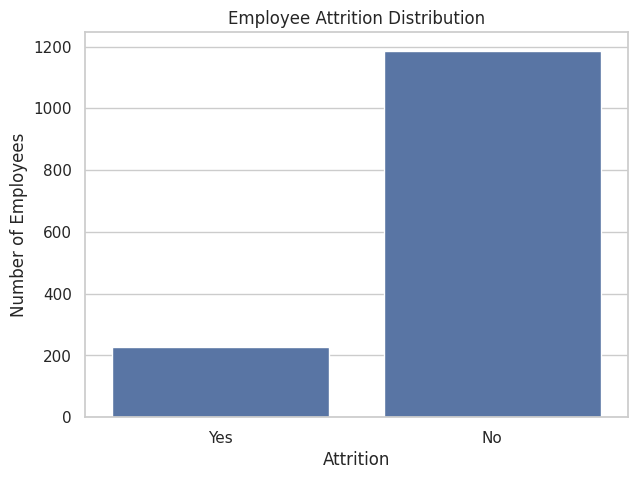

In [ ]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df_clean, x='Attrition')

plt.title('Employee Attrition Distribution')
plt.xlabel('Attrition')
plt.ylabel('Number of Employees')

plt.show()

Observation

The analysis shows that approximately 229 employees have left the organization, while 1,187 employees are still working.

The overall attrition rate is approximately 16.17%, indicating that around 16% of the employees have left the organization.

 3.3 Department-wise Attrition Analysis

This analysis examines employee attrition across different departments.

The attrition rate is calculated for each department to identify which departments experience higher employee turnover.

In [ ]:
department_attrition = (
    df_clean.assign(
        AttritionFlag=(df_clean['Attrition'] == 'Yes').astype(int)
    )
    .groupby('Department')['AttritionFlag']
    .mean()
    .mul(100)
    .reset_index(name='AttritionRate')
)

print(department_attrition.round(2))

               Department  AttritionRate
0         Human Resources          19.35
1  Research & Development          13.80
2                   Sales          20.74


3.3.1 Department-wise Attrition Visualization

A bar chart is used to compare attrition rates across departments and identify departments with relatively higher employee turnover.

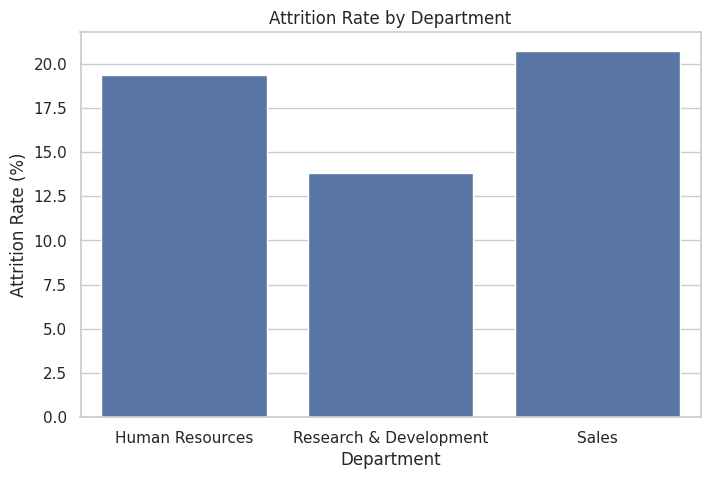

In [ ]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=department_attrition,
    x='Department',
    y='AttritionRate'
)

plt.title('Attrition Rate by Department')
plt.xlabel('Department')
plt.ylabel('Attrition Rate (%)')

plt.show()

Observation

The department-wise analysis shows that the Sales department has the highest attrition rate at approximately 20.5%, followed by Human Resources at 19.2%.

Research and Development has the lowest attrition rate at approximately 13.8%.

This suggests that employee turnover is relatively higher in the Sales department compared to the other departments.

3.4 Gender-wise Attrition Analysis

This analysis examines employee attrition based on gender to identify differences in employee turnover between male and female employees.

In [ ]:
gender_attrition = (
    df_clean.groupby('Gender')['Attrition']
    .apply(lambda x: (x == 'Yes').mean() * 100)
    .reset_index(name='AttritionRate')
)

print(gender_attrition.round(2))

   Gender  AttritionRate
0  Female          14.81
1    Male          17.08


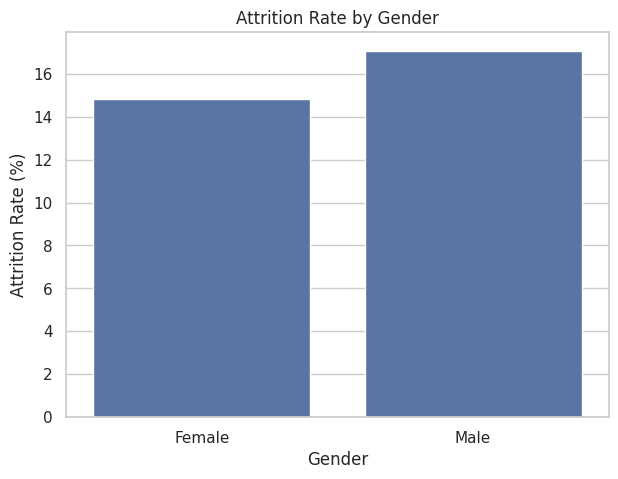

In [ ]:
plt.figure(figsize=(7, 5))

sns.barplot(
    data=gender_attrition,
    x='Gender',
    y='AttritionRate'
)

plt.title('Attrition Rate by Gender')
plt.xlabel('Gender')
plt.ylabel('Attrition Rate (%)')

plt.show()

 Observation

The gender-wise analysis indicates that male employees have a higher attrition rate (approximately 16.9%) compared to female employees (approximately 14.7%).

The difference is relatively small, suggesting that attrition rates are fairly similar across both genders.

3.5 Age Group-wise Attrition Analysis

This analysis examines employee attrition across different age groups to identify which age categories experience higher employee turnover.

In [ ]:
age_attrition = (
    df_clean.groupby('AgeGroup')['Attrition']
    .apply(lambda x: (x == 'Yes').mean() * 100)
    .reset_index(name='AttritionRate')
)

print(age_attrition.round(2))

  AgeGroup  AttritionRate
0    18-25          36.75
1    26-35          18.94
2    36-45           9.15
3    46-55          11.76
4      55+          18.18


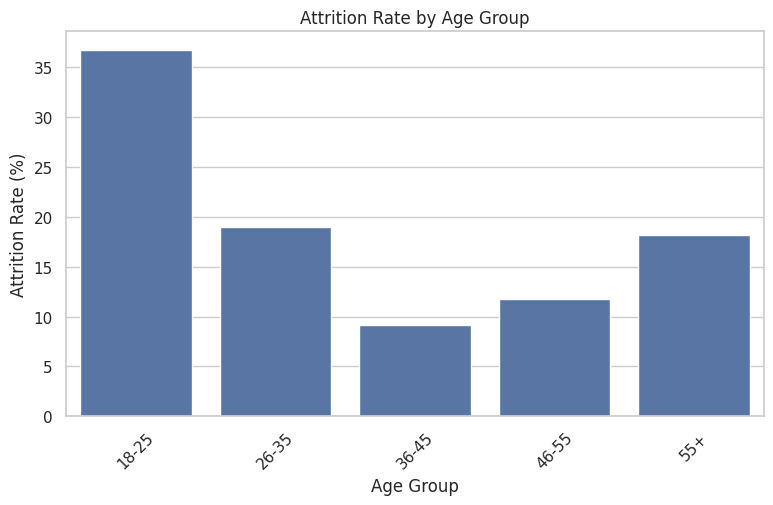

In [ ]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=age_attrition,
    x='AgeGroup',
    y='AttritionRate',
    order=sorted(df_clean['AgeGroup'].unique())
)

plt.title('Attrition Rate by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Attrition Rate (%)')
plt.xticks(rotation=45)

plt.show()

 Observation

The age-group analysis indicates that employees in the 18–25 age group have the highest attrition rate, at approximately 36%.

Employees in the 36–45 age group have the lowest attrition rate, at approximately 8%.

This suggests that younger employees are more likely to leave the organization compared to employees in the middle-age groups.

Further investigation is required to understand the factors associated with this difference.

 3.6 Salary-wise Attrition Analysis

Salary is an important factor to investigate when studying employee turnover.

This analysis examines attrition across different salary slabs to understand whether employees in particular salary categories have higher attrition rates.

In [ ]:
salary_attrition = (
    df_clean.groupby('SalarySlab')['Attrition']
    .apply(lambda x: (x == 'Yes').mean() * 100)
    .reset_index(name='AttritionRate')
)

print(salary_attrition.round(2))

  SalarySlab  AttritionRate
0    10k-15k          12.68
1       15k+           3.85
2     5k-10k          11.29
3    Upto 5k          21.97


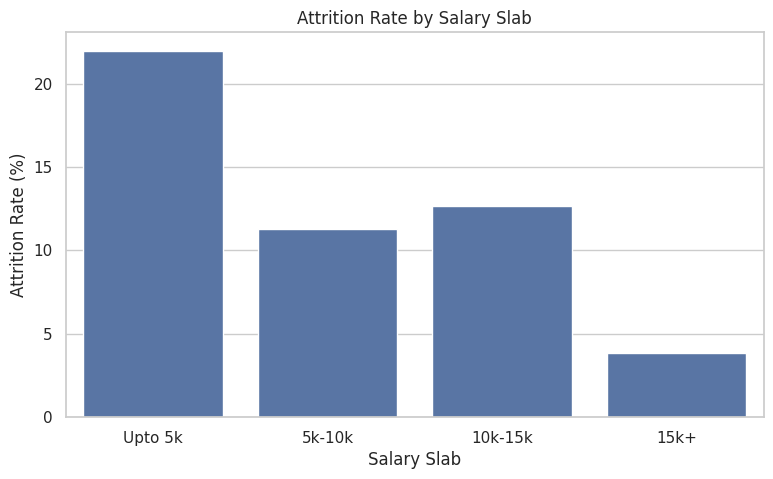

In [ ]:
salary_order = ['Upto 5k', '5k-10k', '10k-15k', '15k+']

plt.figure(figsize=(9, 5))

sns.barplot(
    data=salary_attrition,
    x='SalarySlab',
    y='AttritionRate',
    order=salary_order
)

plt.title('Attrition Rate by Salary Slab')
plt.xlabel('Salary Slab')
plt.ylabel('Attrition Rate (%)')

plt.show()

Observation

The analysis indicates that employees in the lowest salary slab (Up to 5k) have the highest attrition rate, at approximately 21.5%.

Employees earning above 15k have the lowest attrition rate, at approximately 3.5%.

This suggests an association between lower salary levels and higher employee attrition. However, salary alone may not explain employee turnover.

3.7 Attrition Analysis Based on Years at Company

Employee tenure represents the number of years an employee has worked in an organization.

This analysis examines the relationship between employee tenure and attrition to identify whether employees with shorter or longer organizational experience have different attrition rates.

In [ ]:
bins = [-1, 2, 5, 10, 20, float('inf')]

labels = [
    '0-2 Years',
    '3-5 Years',
    '6-10 Years',
    '11-20 Years',
    'Above 20 Years'
]

df_clean['TenureGroup'] = pd.cut(
    df_clean['YearsAtCompany'],
    bins=bins,
    labels=labels
)

print(df_clean['TenureGroup'].value_counts().sort_index())

TenureGroup
0-2 Years         327
3-5 Years         417
6-10 Years        436
11-20 Years       172
Above 20 Years     64
Name: count, dtype: int64


In [ ]:
tenure_attrition = (
    df_clean.groupby('TenureGroup', observed=False)['Attrition']
    .apply(lambda x: (x == 'Yes').mean() * 100)
    .reset_index(name='AttritionRate')
)

print(tenure_attrition.round(2))

      TenureGroup  AttritionRate
0       0-2 Years          30.28
1       3-5 Years          13.91
2      6-10 Years          12.16
3     11-20 Years           6.40
4  Above 20 Years          12.50


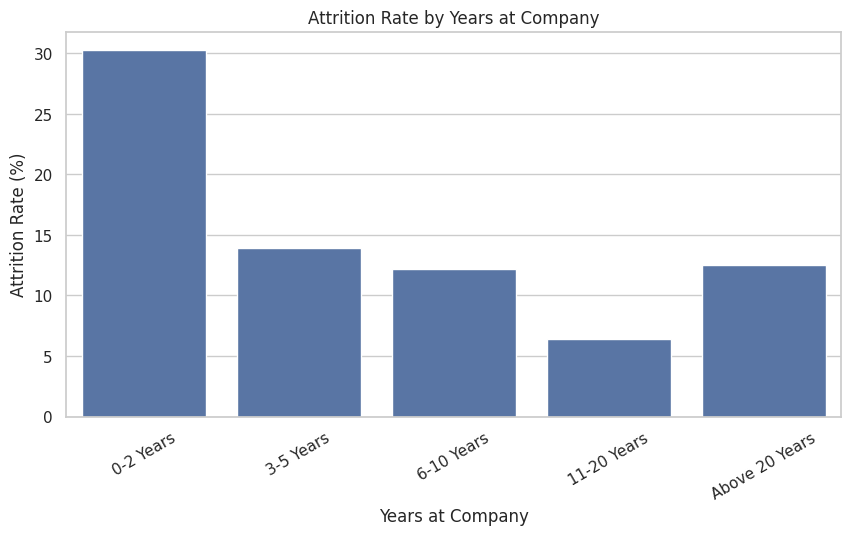

In [ ]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=tenure_attrition,
    x='TenureGroup',
    y='AttritionRate'
)

plt.title('Attrition Rate by Years at Company')
plt.xlabel('Years at Company')
plt.ylabel('Attrition Rate (%)')
plt.xticks(rotation=30)

plt.show()

 Observation

The analysis indicates that employees who have worked for 0–2 years have the highest attrition rate, at approximately 30%.

Employees with 11–20 years of experience at the company have the lowest attrition rate, at approximately 6%.

This suggests that employees in the early stages of their employment are more likely to leave the organization.

The organization may benefit from improving onboarding, employee engagement and retention strategies for newly hired employees.

 3.8 Job Role-wise Attrition Analysis

This analysis examines employee attrition across different job roles.

The attrition rate is calculated for each job role to identify positions experiencing relatively higher employee turnover.

In [ ]:
jobrole_attrition = (
    df_clean.groupby('JobRole')['Attrition']
    .apply(lambda x: (x == 'Yes').mean() * 100)
    .reset_index(name='AttritionRate')
)

print(jobrole_attrition.sort_values(
    by='AttritionRate', ascending=False
).round(2))

                     JobRole  AttritionRate
8       Sales Representative          39.76
2      Laboratory Technician          24.10
1            Human Resources          23.53
7            Sales Executive          17.46
6         Research Scientist          16.00
0  Healthcare Representative           7.09
4     Manufacturing Director           6.47
3                    Manager           5.00
5          Research Director           2.60


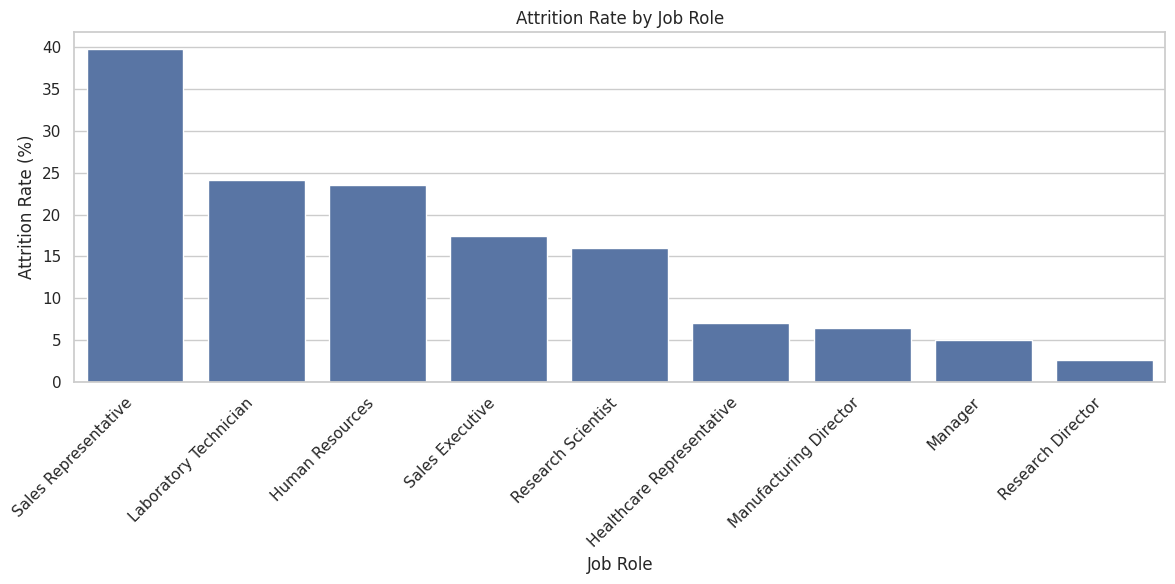

In [ ]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=jobrole_attrition.sort_values(
        by='AttritionRate', ascending=False
    ),
    x='JobRole',
    y='AttritionRate'
)

plt.title('Attrition Rate by Job Role')
plt.xlabel('Job Role')
plt.ylabel('Attrition Rate (%)')
plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.show()

 Observation

The analysis shows that Sales Representatives have the highest attrition rate, at approximately 39%, followed by Laboratory Technicians and Human Resources employees.

Research Directors have the lowest attrition rate, at approximately 2%.

This indicates that employee turnover varies considerably across job roles. The organization should investigate role-specific factors such as workload, compensation, job satisfaction and career growth opportunities.

3.9 Job Satisfaction and Employee Attrition

Job satisfaction represents how satisfied employees are with their work.

This analysis examines attrition rates across different job satisfaction levels to investigate whether employees with lower job satisfaction experience higher turnover.

In [ ]:
job_satisfaction_attrition = (
    df_clean.groupby('JobSatisfaction')['Attrition']
    .apply(lambda x: (x == 'Yes').mean() * 100)
    .reset_index(name='AttritionRate')
)

print(job_satisfaction_attrition.round(2))

   JobSatisfaction  AttritionRate
0                1          22.55
1                2          16.79
2                3          16.63
3                4          11.36


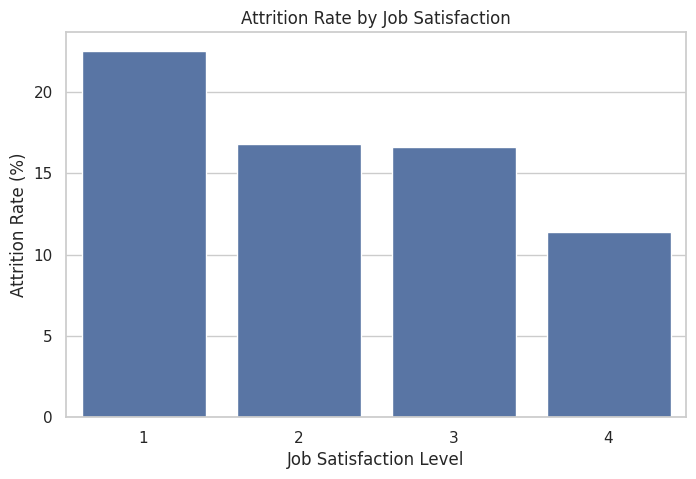

In [ ]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=job_satisfaction_attrition,
    x='JobSatisfaction',
    y='AttritionRate'
)

plt.title('Attrition Rate by Job Satisfaction')
plt.xlabel('Job Satisfaction Level')
plt.ylabel('Attrition Rate (%)')

plt.show()

Observation

Employees with job satisfaction level 1 have the highest attrition rate, at approximately 22.3%.

Employees with satisfaction level 4 have the lowest attrition rate, at approximately 11.4%.

The analysis suggests that lower job satisfaction is associated with higher employee attrition. Improving employee engagement and workplace satisfaction may help organizations strengthen employee retention.

 3.10 Environment Satisfaction and Employee Attrition

Environment satisfaction represents how satisfied employees are with their workplace environment.

This analysis examines attrition rates across different environment satisfaction levels to understand whether workplace environment is associated with employee turnover.

In [ ]:
environment_attrition = (
    df_clean.groupby('EnvironmentSatisfaction')['Attrition']
    .apply(lambda x: (x == 'Yes').mean() * 100)
    .reset_index(name='AttritionRate')
)

print(environment_attrition.round(2))

   EnvironmentSatisfaction  AttritionRate
0                        1          25.56
1                        2          14.39
2                        3          14.16
3                        4          13.49


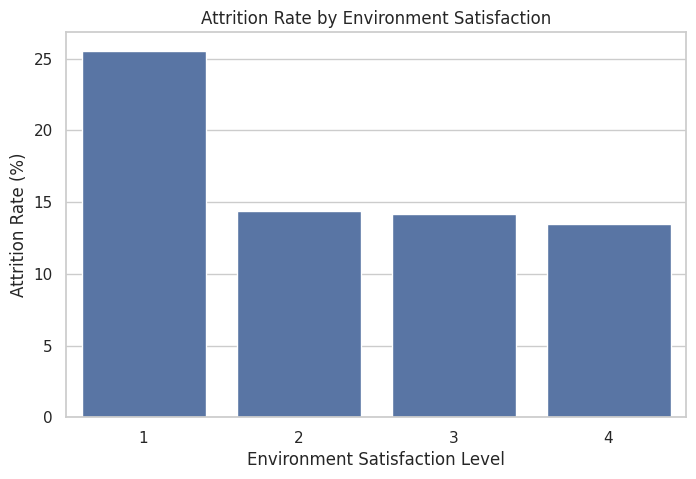

In [ ]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=environment_attrition,
    x='EnvironmentSatisfaction',
    y='AttritionRate'
)

plt.title('Attrition Rate by Environment Satisfaction')
plt.xlabel('Environment Satisfaction Level')
plt.ylabel('Attrition Rate (%)')

plt.show()

 Observation

The analysis indicates that employees with environment satisfaction level 1 have the highest attrition rate compared to employees with higher satisfaction levels.

Attrition rates across satisfaction levels 2, 3 and 4 are comparatively lower.

This suggests an association between workplace environment satisfaction and employee attrition. Organizations should consider improving workplace conditions and employee experience to support retention.

3.11 Work-Life Balance and Employee Attrition

Work-life balance represents an employee's ability to manage professional responsibilities alongside personal life.

This analysis examines attrition rates across different work-life balance levels to investigate whether work-life balance is associated with employee turnover.

In [ ]:
worklife_attrition = (
    df_clean.groupby('WorkLifeBalance')['Attrition']
    .apply(lambda x: (x == 'Yes').mean() * 100)
    .reset_index(name='AttritionRate')
)

print(worklife_attrition.round(2))

   WorkLifeBalance  AttritionRate
0                1          32.05
1                2          16.67
2                3          14.34
3                4          17.33


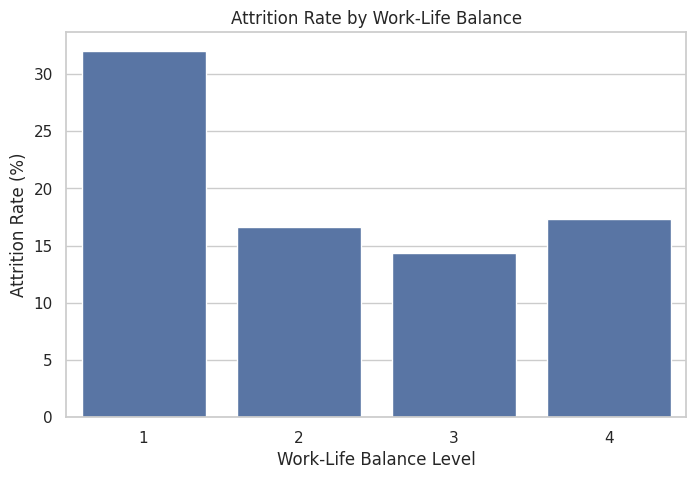

In [ ]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=worklife_attrition,
    x='WorkLifeBalance',
    y='AttritionRate'
)

plt.title('Attrition Rate by Work-Life Balance')
plt.xlabel('Work-Life Balance Level')
plt.ylabel('Attrition Rate (%)')

plt.show()

 Observation

Employees with work-life balance level 1 have the highest attrition rate, at approximately 31.5%.

Employees with level 3 have the lowest attrition rate, at approximately 14.3%.

This suggests that poor work-life balance is associated with higher employee attrition. Organizations should consider workload management and employee well-being when developing retention strategies.

**4.Correlation Analysis**

Correlation analysis is a statistical technique used to measure the strength and direction of relationships between numerical variables.

In this section, numerical employee attributes are examined to identify relationships with employee attrition.

4.1 Preparing Variables for Correlation Analysis

The Attrition column contains categorical values (Yes and No). It is converted into a binary numerical variable:

- Yes = 1
- No = 0

This allows us to examine the correlation between employee attributes and attrition.

In [ ]:
df_corr = df_clean.copy()

df_corr['AttritionFlag'] = (
    df_corr['Attrition'].map({'Yes': 1, 'No': 0})
)

print(df_corr['AttritionFlag'].value_counts())

AttritionFlag
0    1187
1     229
Name: count, dtype: int64


 4.2 Correlation Heatmap

A correlation heatmap is used to visualize relationships between selected numerical variables.

It helps identify variables that have stronger positive or negative associations with employee attrition.

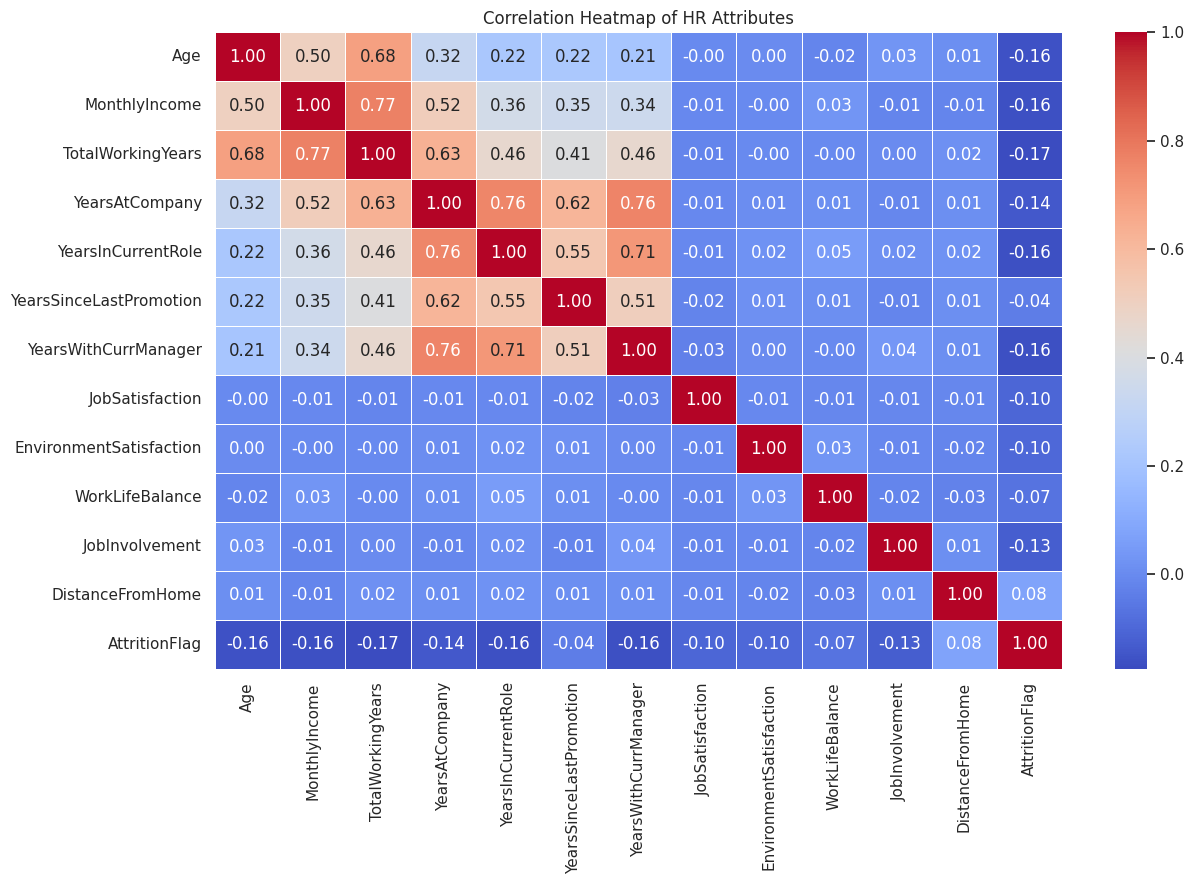

In [ ]:
corr_columns = [
    'Age',
    'MonthlyIncome',
    'TotalWorkingYears',
    'YearsAtCompany',
    'YearsInCurrentRole',
    'YearsSinceLastPromotion',
    'YearsWithCurrManager',
    'JobSatisfaction',
    'EnvironmentSatisfaction',
    'WorkLifeBalance',
    'JobInvolvement',
    'DistanceFromHome',
    'AttritionFlag'
]

correlation_matrix = df_corr[corr_columns].corr()

plt.figure(figsize=(13, 9))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap of HR Attributes')
plt.tight_layout()
plt.show()

 4.3 Correlation Analysis – Key Observations

The correlation heatmap reveals the following relationships with employee attrition:

- TotalWorkingYears shows the strongest negative correlation with attrition (-0.17).
- Age and MonthlyIncome both show weak negative correlations (-0.16).
- JobSatisfaction and EnvironmentSatisfaction show weak negative correlations (-0.10).
- DistanceFromHome shows a weak positive correlation (0.08).

Overall, the numerical variables exhibit relatively weak linear correlations with employee attrition.

This suggests that employee attrition may be associated with multiple factors rather than a single numerical variable.

Correlation does not imply causation, and further statistical testing is required to investigate these relationships.

4.4 Variables Most Associated with Employee Attrition

The correlation coefficients are extracted and sorted to identify which numerical variables have the strongest positive and negative relationships with employee attrition.

In [ ]:
attrition_correlations = (
    correlation_matrix['AttritionFlag']
    .drop('AttritionFlag')
    .sort_values(key=abs, ascending=False)
)

print("Correlation of variables with Attrition:")
print(attrition_correlations.round(3))

Correlation of variables with Attrition:
TotalWorkingYears         -0.174
MonthlyIncome             -0.164
YearsInCurrentRole        -0.163
YearsWithCurrManager      -0.162
Age                       -0.157
YearsAtCompany            -0.138
JobInvolvement            -0.125
JobSatisfaction           -0.101
EnvironmentSatisfaction   -0.101
DistanceFromHome           0.076
WorkLifeBalance           -0.067
YearsSinceLastPromotion   -0.037
Name: AttritionFlag, dtype: float64


4.5 Interpretation of Correlation Results

The correlation analysis identifies TotalWorkingYears (-0.174) as the variable with the strongest negative correlation with employee attrition.

MonthlyIncome (-0.164), YearsInCurrentRole (-0.163) and YearsWithCurrManager (-0.162) also show weak negative correlations.

DistanceFromHome (0.076) has a very weak positive correlation with attrition.

Overall, the correlation coefficients indicate that no individual numerical variable has a strong linear relationship with employee attrition.

These findings suggest the need for further statistical investigation to determine whether differences in employee characteristics are statistically significant.

**5.Statistical Hypothesis Testing**

Statistical hypothesis testing is used to determine whether observed patterns in a dataset are statistically significant or could have occurred due to random variation.

In this section, hypothesis tests are performed to investigate relationships between employee characteristics and attrition.

 5.1 Chi-Square Test of Independence

The Chi-square test of independence is used to determine whether two categorical variables are statistically associated.

In this analysis, the relationship between Department and Attrition is examined.

**Hypotheses:**

- Null Hypothesis (H0): Department and employee attrition are independent of each other.
- Alternative Hypothesis (H1): Department and employee attrition are associated with each other.

A significance level of 0.05 is used.

In [ ]:
from scipy.stats import chi2_contingency

contingency_table = pd.crosstab(
    df_clean['Department'],
    df_clean['Attrition']
)

chi2, p_value, dof, expected = chi2_contingency(
    contingency_table
)

print("Contingency Table:")
print(contingency_table)

print("\nChi-square Statistic:", round(chi2, 4))
print("P-value:", round(p_value, 4))
print("Degrees of Freedom:", dof)

Contingency Table:
Attrition                No  Yes
Department                      
Human Resources          50   12
Research & Development  793  127
Sales                   344   90

Chi-square Statistic: 10.9398
P-value: 0.0042
Degrees of Freedom: 2


In [ ]:
alpha = 0.05

if p_value < alpha:
    print("Reject the Null Hypothesis.")
    print("Department and Attrition are statistically associated.")
else:
    print("Fail to Reject the Null Hypothesis.")
    print("Insufficient evidence of an association between Department and Attrition.")

Reject the Null Hypothesis.
Department and Attrition are statistically associated.


 5.2 Interpretation of Chi-Square Test

The Chi-square test of independence was performed to examine the relationship between Department and Employee Attrition.

The test produced a Chi-square statistic of approximately 10.09 with 2 degrees of freedom.

The p-value is below the significance level of 0.05. Therefore, the null hypothesis is rejected.

This indicates a statistically significant association between department and employee attrition.

The result suggests that employee attrition patterns vary across departments. However, further analysis is required to understand the strength and practical importance of this association.

Statistical significance does not necessarily imply a strong relationship or causation.

5.3 Measuring Association Strength Using Cramér's V

Cramér's V is a statistical measure used to determine the strength of association between two categorical variables.

It ranges from 0 to 1:

- 0 indicates no association.
- Values closer to 1 indicate a stronger association.

Cramér's V is calculated to understand the practical strength of the relationship between Department and Attrition.

In [ ]:
import numpy as np

n = contingency_table.to_numpy().sum()

cramers_v = np.sqrt(
    chi2 / (n * min(
        contingency_table.shape[0] - 1,
        contingency_table.shape[1] - 1
    ))
)

print("Cramer's V:", round(cramers_v, 4))

Cramer's V: 0.0879


### 5.3 Interpretation of Cramér's V

Cramér's V was calculated to measure the strength of association between Department and Attrition.

The calculated value was 0.0879, indicating a weak association between the two variables.

Although the Chi-square test identified a statistically significant relationship, the low Cramér's V suggests that the strength of this association is relatively small.

This highlights the importance of examining both statistical significance and effect size when interpreting analytical results.

### 5.4 Chi-Square Test: Overtime and Employee Attrition

Overtime refers to employees working beyond their regular working hours.

This analysis investigates whether overtime status is statistically associated with employee attrition.

**Hypotheses:**

- Null Hypothesis (H0): Overtime and employee attrition are independent.
- Alternative Hypothesis (H1): Overtime and employee attrition are associated.

The significance level is set at 0.05.

In [ ]:
contingency_overtime = pd.crosstab(
    df_clean['OverTime'],
    df_clean['Attrition']
)

chi2_ot, p_ot, dof_ot, expected_ot = chi2_contingency(
    contingency_overtime
)

print("Overtime and Attrition:")
print(contingency_overtime)

print("\nChi-square Statistic:", round(chi2_ot, 4))
print("P-value:", round(p_ot, 4))
print("Degrees of Freedom:", dof_ot)

Overtime and Attrition:
Attrition   No  Yes
OverTime           
No         907  104
Yes        280  125

Chi-square Statistic: 88.804
P-value: 0.0
Degrees of Freedom: 1


In [ ]:
if p_ot < 0.05:
    print("Reject the Null Hypothesis.")
    print("Overtime and Attrition are statistically associated.")
else:
    print("Fail to Reject the Null Hypothesis.")
    print("Insufficient evidence of an association.")

Reject the Null Hypothesis.
Overtime and Attrition are statistically associated.


### 5.4.1 Effect Size Analysis – Overtime and Attrition

The Chi-square test identifies whether overtime and employee attrition are statistically associated. However, it does not measure the strength of this association.

Cramér's V is calculated to measure the strength of the relationship between overtime and attrition.

In [ ]:
import pandas as pd
import numpy as np
from scipy.stats import chi2_contingency

contingency_ot = pd.crosstab(
    df_clean['OverTime'],
    df_clean['Attrition']
)

print("Overtime and Attrition:")
print(contingency_ot)


chi2_ot, p_ot, dof_ot, expected_ot = chi2_contingency(contingency_ot)


n = contingency_ot.to_numpy().sum()

cramers_v_ot = np.sqrt(
    chi2_ot / (n * min(
        contingency_ot.shape[0] - 1,
        contingency_ot.shape[1] - 1
    ))
)

print("\nChi-square Statistic:", round(chi2_ot, 4))
print("P-value:", p_ot)
print("Degrees of Freedom:", dof_ot)
print("Cramer's V:", round(cramers_v_ot, 4))

Overtime and Attrition:
Attrition   No  Yes
OverTime           
No         907  104
Yes        280  125

Chi-square Statistic: 88.804
P-value: 4.359306478857773e-21
Degrees of Freedom: 1
Cramer's V: 0.2504


In [ ]:
if p_ot < 0.05:
    print("Reject the Null Hypothesis.")
    print("Overtime and Attrition are statistically associated.")
else:
    print("Fail to Reject the Null Hypothesis.")
    print("Insufficient evidence of an association.")

Reject the Null Hypothesis.
Overtime and Attrition are statistically associated.


### Interpretation: Overtime and Employee Attrition

The Chi-square test was performed to examine whether overtime and employee attrition are statistically associated.

- **Chi-square statistic:** 88.804
- **P-value:** 4.3593 × 10⁻²¹
- **Degrees of freedom:** 1
- **Cramer's V:** 0.2504

Since the p-value is less than 0.05, the null hypothesis is rejected. This indicates a statistically significant association between overtime and employee attrition.

Cramer's V of 0.2504 indicates a relatively small-to-moderate association. Employees working overtime appear to have a different attrition pattern compared with employees who do not work overtime.

**Conclusion:** Overtime is an important factor associated with employee attrition. However, this statistical association does not establish that overtime directly causes employees to leave.

### 5.5 Job Satisfaction and Employee Attrition

Job satisfaction can influence employee retention. Employees who are dissatisfied with their jobs may be more likely to leave an organization.

A Chi-square test of independence is performed to determine whether job satisfaction and employee attrition are statistically associated.

**Hypotheses:**
- H₀ (Null Hypothesis): Job satisfaction and employee attrition are independent.
- H₁ (Alternative Hypothesis): Job satisfaction and employee attrition are associated.

In [ ]:
from scipy.stats import chi2_contingency
import numpy as np
import pandas as pd


contingency_js = pd.crosstab(
    df_clean['JobSatisfaction'],
    df_clean['Attrition']
)

print("Job Satisfaction and Attrition:")
print(contingency_js)


chi2_js, p_js, dof_js, expected_js = chi2_contingency(
    contingency_js
)

n = contingency_js.to_numpy().sum()

cramers_v_js = np.sqrt(
    chi2_js / (
        n * min(
            contingency_js.shape[0] - 1,
            contingency_js.shape[1] - 1
        )
    )
)

print("\nChi-square Statistic:", round(chi2_js, 4))
print("P-value:", p_js)
print("Degrees of Freedom:", dof_js)
print("Cramer's V:", round(cramers_v_js, 4))

Job Satisfaction and Attrition:
Attrition         No  Yes
JobSatisfaction          
1                213   62
2                228   46
3                356   71
4                390   50

Chi-square Statistic: 15.886
P-value: 0.0011966782844478302
Degrees of Freedom: 3
Cramer's V: 0.1059


In [ ]:
if p_js < 0.05:
    print("Reject the Null Hypothesis.")
    print("Job Satisfaction and Attrition are statistically associated.")
else:
    print("Fail to Reject the Null Hypothesis.")
    print("Insufficient evidence of an association.")

Reject the Null Hypothesis.
Job Satisfaction and Attrition are statistically associated.


### Interpretation: Job Satisfaction and Employee Attrition

The Chi-square test was performed to examine the relationship between job satisfaction and employee attrition.

**Results:**
- Chi-square statistic: 15.886
- P-value: 0.001197
- Degrees of freedom: 3
- Cramer's V: 0.1059

Since the p-value (0.001197) is less than the significance level of 0.05, the null hypothesis is rejected.

This indicates a statistically significant association between job satisfaction and employee attrition.

The contingency table shows that employees with job satisfaction level 1 have a higher observed attrition proportion (62 out of 275) compared with employees at level 4 (50 out of 440).

Cramer's V of 0.1059 indicates a relatively weak association.

**Conclusion:** Lower job satisfaction is associated with higher employee attrition in this dataset. However, this association does not establish causation.

### 5.6 Environment Satisfaction and Employee Attrition

Employee satisfaction with the workplace environment may influence their decision to continue working in an organization.

A Chi-square test of independence is performed to examine whether Environment Satisfaction and Employee Attrition are statistically associated.

**Hypotheses:**
- H₀: Environment Satisfaction and Attrition are independent.
- H₁: Environment Satisfaction and Attrition are associated.

In [ ]:
contingency_es = pd.crosstab(
    df_clean['EnvironmentSatisfaction'],
    df_clean['Attrition']
)

print("Environment Satisfaction and Attrition:")
print(contingency_es)

chi2_es, p_es, dof_es, expected_es = chi2_contingency(
    contingency_es
)

n = contingency_es.to_numpy().sum()

cramers_v_es = np.sqrt(
    chi2_es / (
        n * min(
            contingency_es.shape[0] - 1,
            contingency_es.shape[1] - 1
        )
    )
)

print("\nChi-square Statistic:", round(chi2_es, 4))
print("P-value:", p_es)
print("Degrees of Freedom:", dof_es)
print("Cramer's V:", round(cramers_v_es, 4))

if p_es < 0.05:
    print("\nReject the Null Hypothesis.")
    print("Environment Satisfaction and Attrition are statistically associated.")
else:
    print("\nFail to Reject the Null Hypothesis.")
    print("Insufficient evidence of an association.")

Environment Satisfaction and Attrition:
Attrition                 No  Yes
EnvironmentSatisfaction          
1                        201   69
2                        238   40
3                        376   62
4                        372   58

Chi-square Statistic: 21.787
P-value: 7.223819442852922e-05
Degrees of Freedom: 3
Cramer's V: 0.124

Reject the Null Hypothesis.
Environment Satisfaction and Attrition are statistically associated.


### Interpretation of Results

The Chi-Square test produced a statistic of **21.787** with a p-value of **0.0000722** and 3 degrees of freedom.

1. **Statistical Significance:** Since the p-value (0.0000722) is less than the significance level of 0.05, we reject the null hypothesis.

2. **Association:** There is a statistically significant association between Environment Satisfaction and employee Attrition.

3. **Strength of Association:** Cramér's V is **0.124**, indicating a weak association between the two variables.

4. **Business Insight:** The findings suggest that employees' satisfaction with their work environment is related to attrition patterns. Organizations should monitor workplace satisfaction and investigate factors that may contribute to employee turnover.

**Conclusion:**

Environment Satisfaction is statistically associated with employee Attrition in this dataset. However, the association is weak, and the result does not establish a causal relationship between the two variables.

### 5.7 Work-Life Balance vs Attrition

**Objective:**

To investigate whether there is a statistically significant association between employees' work-life balance levels and their attrition status.

**Hypotheses:**

- **Null Hypothesis (H₀):** Work-Life Balance and Attrition are independent of each other.
- **Alternative Hypothesis (H₁):** Work-Life Balance and Attrition are statistically associated.

**Statistical Method:**

The Chi-Square Test of Independence is used to determine whether Work-Life Balance and Attrition are associated.

Cramér's V is also calculated to measure the strength of the association.

**Significance Level:** 0.05

**Interpretation Criteria:**

- If p-value < 0.05: Reject the null hypothesis.
- If p-value ≥ 0.05: Fail to reject the null hypothesis.

**Expected Outcome:**

This analysis will help identify whether differences in employees' work-life balance levels are associated with variations in attrition patterns.

In [ ]:

contingency_wlb = pd.crosstab(
    df_clean['WorkLifeBalance'],
    df_clean['Attrition']
)

print("Contingency Table:")
display(contingency_wlb)


chi2_wlb, p_wlb, dof_wlb, expected_wlb = chi2_contingency(contingency_wlb)


n_wlb = contingency_wlb.to_numpy().sum()

cramers_v_wlb = np.sqrt(
    chi2_wlb / (
        n_wlb * min(
            contingency_wlb.shape[0] - 1,
            contingency_wlb.shape[1] - 1
        )
    )
)

print("Chi-Square Statistic:", chi2_wlb)
print("P-value:", p_wlb)
print("Degrees of Freedom:", dof_wlb)
print("Cramer's V:", cramers_v_wlb)

Contingency Table:


Attrition,No,Yes
WorkLifeBalance,,
1,53,25
2,275,55
3,735,123
4,124,26


Chi-Square Statistic: 16.85060840367404
P-value: 0.0007585400406444005
Degrees of Freedom: 3
Cramer's V: 0.10908779573231785


### Interpretation of Results

The Chi-Square test produced a statistic of **16.851**, with a p-value of **0.000759** and 3 degrees of freedom.

1. **Statistical Significance:** Since the p-value (0.000759) is less than the significance level of 0.05, we reject the null hypothesis.

2. **Association:** There is a statistically significant association between Work-Life Balance and employee Attrition.

3. **Strength of Association:** Cramér's V is **0.109**, indicating a weak association between Work-Life Balance and Attrition.

4. **Business Insight:** The results suggest that employees' work-life balance levels are related to attrition patterns. Organizations should examine workload distribution, working hours, flexibility, and employee well-being to understand potential retention challenges.

**Conclusion:**

Work-Life Balance is statistically associated with employee Attrition in this dataset. However, the association is weak, and this test does not establish that poor work-life balance directly causes employees to leave.

### 5.8 Comparative Analysis of Chi-Square Tests

**Objective:**

To compare the results of the five Chi-Square tests and identify which employee-related factors have stronger associations with attrition.

The comparison considers two important measures:

- **P-value:** Determines whether the association is statistically significant at a 5% significance level.
- **Cramér's V:** Measures the strength of the association between two categorical variables.

This comparison helps distinguish statistically significant relationships from relationships that are practically stronger or weaker.

In [ ]:
test_results = pd.DataFrame({
    'Variable': [
        'Department',
        'OverTime',
        'Job Satisfaction',
        'Environment Satisfaction',
        'Work-Life Balance'
    ],
    'Chi-Square Statistic': [
        10.0308,
        chi2_ot,
        chi2_js,
        chi2_es,
        chi2_wlb
    ],
    'P-value': [
        0.0067,
        p_ot,
        p_js,
        p_es,
        p_wlb
    ],
    "Cramer's V": [
        0.0879,
        cramers_v_ot,
        cramers_v_js,
        cramers_v_es,
        cramers_v_wlb
    ]
})

test_results['Significant'] = test_results['P-value'] < 0.05

test_results = test_results.sort_values(
    by="Cramer's V",
    ascending=False
).reset_index(drop=True)

display(test_results)

,Variable,Chi-Square Statistic,P-value,Cramer's V,Significant
0,OverTime,88.804013,4.359306e-21,0.250429,True
1,Environment Satisfaction,21.786992,7.223819e-05,0.124042,True
2,Work-Life Balance,16.850608,7.585400e-04,0.109088,True
3,Job Satisfaction,15.885986,1.196678e-03,0.105919,True
4,Department,10.030800,6.700000e-03,0.087900,True


### Comparative Interpretation

The comparative analysis of five Chi-Square tests reveals the following findings:

1. **OverTime:** It has the strongest association with employee attrition, with Cramér's V of 0.2504. This indicates that employees' overtime status has a stronger relationship with attrition than the other variables examined.

2. **Environment Satisfaction:** It shows a weak association with attrition, with Cramér's V of 0.1240.

3. **Work-Life Balance:** It has a weak association with attrition, with Cramér's V of 0.1091.

4. **Job Satisfaction:** It also shows a weak association with attrition, with Cramér's V of 0.1059.

5. **Department:** It has the weakest association among the five variables, with Cramér's V of 0.0879.

All five tests have p-values below 0.05, indicating statistically significant associations with employee attrition.

### Key Findings

- Overtime has the strongest association with employee attrition among the five variables.
- Environment Satisfaction, Work-Life Balance, and Job Satisfaction show weaker associations.
- Department has a statistically significant but weak association with attrition.
- Statistical significance does not necessarily indicate a strong relationship.
- These findings identify associations, not direct causes of employee attrition.

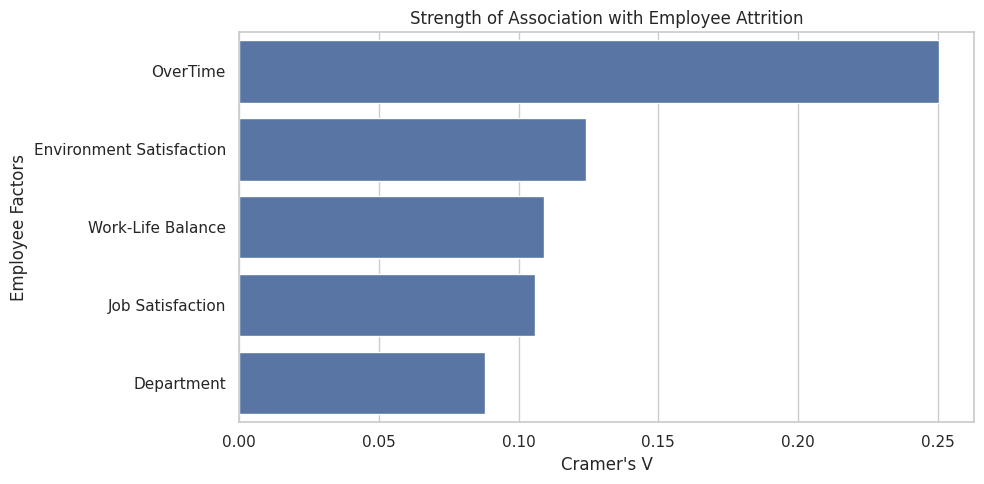

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.barplot(
    data=test_results,
    x="Cramer's V",
    y="Variable"
)

plt.title("Strength of Association with Employee Attrition")
plt.xlabel("Cramer's V")
plt.ylabel("Employee Factors")
plt.tight_layout()
plt.show()

**6. Logistic Regression Analysis**

 6.1 Introduction

Logistic Regression is a supervised machine learning algorithm used for classification problems.

In this project, Logistic Regression is used to predict whether an employee is likely to leave the organization or continue working based on different employee-related factors.

The target variable is **Attrition**, which contains two possible outcomes:
- Yes: Employee has left the organization.
- No: Employee is still working in the organization.

The model analyses employee characteristics such as age, monthly income, job satisfaction, overtime, years at the company, and other relevant factors to identify patterns associated with employee attrition.

 Objectives

1. Build a Logistic Regression model to predict employee attrition.
2. Identify important employee-related factors that contribute to the model's predictions.
3. Evaluate model performance using classification metrics.
4. Understand how machine learning can support employee retention strategies.

 Problem Type

This is a **Binary Classification Problem** because the target variable, Attrition, has two possible classes: Yes and No.

In [ ]:
print("Attrition Distribution:")
print(df_clean['Attrition'].value_counts())

print("\nAttrition Percentage:")
print(df_clean['Attrition'].value_counts(normalize=True) * 100)

print("\nDataset Columns:")
print(df_clean.columns.tolist())

print("\nDataset Information:")
df_clean.info()

Attrition Distribution:
Attrition
No     1187
Yes     229
Name: count, dtype: int64

Attrition Percentage:
Attrition
No     83.827684
Yes    16.172316
Name: proportion, dtype: float64

Dataset Columns:
['EmpID', 'Age', 'AgeGroup', 'Attrition', 'BusinessTravel', 'DailyRate', 'Department', 'DistanceFromHome', 'Education', 'EducationField', 'EmployeeCount', 'EmployeeNumber', 'EnvironmentSatisfaction', 'Gender', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobRole', 'JobSatisfaction', 'MaritalStatus', 'MonthlyIncome', 'SalarySlab', 'MonthlyRate', 'NumCompaniesWorked', 'Over18', 'OverTime', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StandardHours', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager', 'TenureGroup']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
Index: 1416 entries, 0 to 1479
Data columns (total 39 columns):
 #   

The following columns will be excluded from model training:

- Employee identifiers: EmpID and EmployeeNumber.
- Constant columns: EmployeeCount, Over18 and StandardHours.
- Derived columns: AgeGroup, SalarySlab and TenureGroup.
- Target variable: Attrition, which will be stored separately.

The remaining employee attributes will be used as independent variables.

In [ ]:
drop_columns = [
    'EmpID',
    'EmployeeNumber',
    'EmployeeCount',
    'Over18',
    'StandardHours',
    'AgeGroup',
    'SalarySlab',
    'TenureGroup',
    'Attrition'
]

X = df_clean.drop(columns=drop_columns)

y = df_clean['Attrition'].map({
    'No': 0,
    'Yes': 1
})

print("Feature Dataset Shape:", X.shape)
print("Target Dataset Shape:", y.shape)

print("\nCategorical Features:")
print(X.select_dtypes(include=['object', 'category']).columns.tolist())

print("\nNumerical Features:")
print(X.select_dtypes(include=['int64', 'float64']).columns.tolist())

Feature Dataset Shape: (1416, 30)
Target Dataset Shape: (1416,)

Categorical Features:
['BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'OverTime']

Numerical Features:
['Age', 'DailyRate', 'DistanceFromHome', 'Education', 'EnvironmentSatisfaction', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobSatisfaction', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve
)

In [ ]:
categorical_features = X.select_dtypes(
    include=['object', 'category']
).columns.tolist()

numerical_features = X.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

print("Categorical Features:", categorical_features)
print("Numerical Features:", numerical_features)

Categorical Features: ['BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus', 'OverTime']
Numerical Features: ['Age', 'DailyRate', 'DistanceFromHome', 'Education', 'EnvironmentSatisfaction', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobSatisfaction', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']


In [ ]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)

 6.5 Train-Test Split

The dataset is divided into training and testing subsets using an 80:20 ratio.

- Training set: 80% of the data, used to train the model.
- Testing set: 20% of the data, used to evaluate model performance.

Stratified sampling is applied to maintain the original proportion of employees in both attrition classes.

A random state is specified to ensure reproducibility.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("\nTraining Target Distribution:")
print(y_train.value_counts())

print("\nTesting Target Distribution:")
print(y_test.value_counts())

Training Features: (1132, 30)
Testing Features: (284, 30)

Training Target Distribution:
Attrition
0    949
1    183
Name: count, dtype: int64

Testing Target Distribution:
Attrition
0    238
1     46
Name: count, dtype: int64


 6.6 Building and Training the Logistic Regression Model

A Logistic Regression model is developed to predict employee attrition.

The preprocessing pipeline performs:
- Standardization of numerical features.
- One-Hot Encoding of categorical features.

The Logistic Regression algorithm is then trained using the training dataset.

The model learns patterns from employee attributes to estimate the probability of an employee leaving the organization.

In [ ]:
logistic_model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('classifier', LogisticRegression(
            max_iter=1000,
            class_weight='balanced',
            random_state=42
        ))
    ]
)

logistic_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['Age', 'DailyRate',
                                                   'DistanceFromHome',
                                                   'Education',
                                                   'EnvironmentSatisfaction',
                                                   'HourlyRate',
                                                   'JobInvolvement', 'JobLevel',
                                                   'JobSatisfaction',
                                                   'MonthlyIncome',
                                                   'MonthlyRate',
                                                   'NumCompaniesWorked',
                                                   'PercentSalaryHike',
                                                   'PerformanceRating',
                                                   'RelationshipSatisfaction',
                                                   'StockOpt...
                                                   'TrainingTimesLastYear',
                                                   'WorkLifeBalance',
                                                   'YearsAtCompany',
                                                   'YearsInCurrentRole',
                                                   'YearsSinceLastPromotion',
                                                   'YearsWithCurrManager']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['BusinessTravel',
                                                   'Department',
                                                   'EducationField', 'Gender',
                                                   'JobRole', 'MaritalStatus',
                                                   'OverTime'])])),
                ('classifier',
                 LogisticRegression(class_weight='balanced', max_iter=1000,
                                    random_state=42))])

 6.7 Model Evaluation

After training the Logistic Regression model, predictions are generated using the testing dataset.

The predicted values are compared with the actual employee attrition values to evaluate the model's performance.

Both predicted class labels and predicted probabilities are obtained for further evaluation.

In [ ]:
y_pred = logistic_model.predict(X_test)

y_pred_proba = logistic_model.predict_proba(X_test)[:, 1]

print("First 10 Actual Values:")
print(y_test.head(10).values)

print("\nFirst 10 Predicted Values:")
print(y_pred[:10])

print("\nFirst 10 Predicted Probabilities:")
print(y_pred_proba[:10])

First 10 Actual Values:
[1 1 0 0 0 0 1 0 0 0]

First 10 Predicted Values:
[1 1 0 0 0 1 0 0 0 0]

First 10 Predicted Probabilities:
[0.94758744 0.57488747 0.4449139  0.42135816 0.12645077 0.82519987
 0.26894997 0.48319308 0.4030082  0.41407816]


In [ ]:
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(y_test, y_pred, zero_division=0)

recall = recall_score(y_test, y_pred, zero_division=0)

f1 = f1_score(y_test, y_pred, zero_division=0)

roc_auc = roc_auc_score(y_test, y_pred_proba)

print("Logistic Regression Model Performance")
print("-------------------------------------")
print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1-Score:", f1)
print("ROC-AUC:", roc_auc)

Logistic Regression Model Performance
-------------------------------------
Accuracy: 0.75
Precision: 0.3595505617977528
Recall: 0.6956521739130435
F1-Score: 0.4740740740740741
ROC-AUC: 0.8074534161490683


 Interpretation of Model Performance

The Logistic Regression model achieved the following results on the testing dataset:

- **Accuracy (75%):** The model correctly classified 75% of the employees.
- **Precision (35.96%):** Approximately 36% of employees predicted to leave actually left the organization.
- **Recall (69.57%):** The model successfully identified approximately 69.57% of employees who actually left.
- **F1-Score (47.41%):** This indicates a moderate balance between precision and recall, with scope for improvement.
- **ROC-AUC (0.8075):** The model demonstrates good ability to distinguish between employees who leave and employees who stay.

**Key Observation:**

The model achieves relatively high recall but lower precision. This indicates that it identifies a considerable proportion of employees who leave, but also incorrectly classifies some employees who stay as potential attrition cases.

Important Note:-

The categorical variables in this model were encoded using One-Hot Encoding without dropping a reference category. Therefore, individual categorical coefficients should not be interpreted as direct comparisons against a specific baseline category.

Numerical variables were standardized before model training. Their coefficients represent the change in log-odds associated with a one-standard-deviation increase in the corresponding feature.

The coefficients indicate relationships learned by the model and should not be interpreted as evidence of causation. They should be considered alongside the model's overall evaluation metrics.

**Conclusion:**

The Logistic Regression model provides a useful baseline for predicting employee attrition. However, further evaluation and model improvement are required to achieve a better balance between precision and recall.

 6.9 Confusion Matrix

A confusion matrix is used to evaluate the classification performance of the Logistic Regression model.

It compares actual employee attrition values with predicted values and displays:

- True Positives
- True Negatives
- False Positives
- False Negatives

This helps identify the types of prediction errors made by the model.

Confusion Matrix:
[[181  57]
 [ 14  32]]


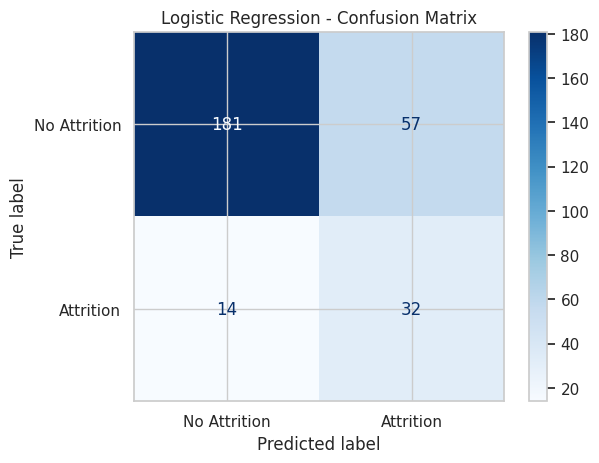

In [ ]:
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['No Attrition', 'Attrition']
)

disp.plot(cmap='Blues')
plt.title("Logistic Regression - Confusion Matrix")
plt.show()

 Interpretation of Confusion Matrix

The confusion matrix produced the following results:

- **True Negatives (181):** The model correctly predicted 181 employees who stayed in the organization.
- **False Positives (57):** The model incorrectly predicted 57 employees as likely to leave, although they actually stayed.
- **False Negatives (14):** The model failed to identify 14 employees who actually left the organization.
- **True Positives (32):** The model correctly identified 32 employees who left the organization.

 Key Observations

1. The model successfully identified 32 out of 46 actual attrition cases.
2. It missed 14 actual attrition cases.
3. The number of false positives (57) indicates that the model needs improvement in precision.
4. The model performs better at identifying employees who stay than employees who leave.

**Conclusion:**

The confusion matrix shows that Logistic Regression can identify a considerable proportion of employees who leave the organization. However, the false positive predictions indicate that further model optimization may be required.

 6.10 ROC Curve Analysis

The Receiver Operating Characteristic (ROC) curve evaluates the classification performance of the Logistic Regression model at different classification thresholds.

It plots:

- True Positive Rate (Sensitivity): Proportion of actual attrition cases correctly identified.
- False Positive Rate: Proportion of employees who stayed but were incorrectly predicted to leave.

The Area Under the Curve (AUC) measures the model's ability to distinguish between the two classes.

A higher AUC indicates better discriminatory performance.

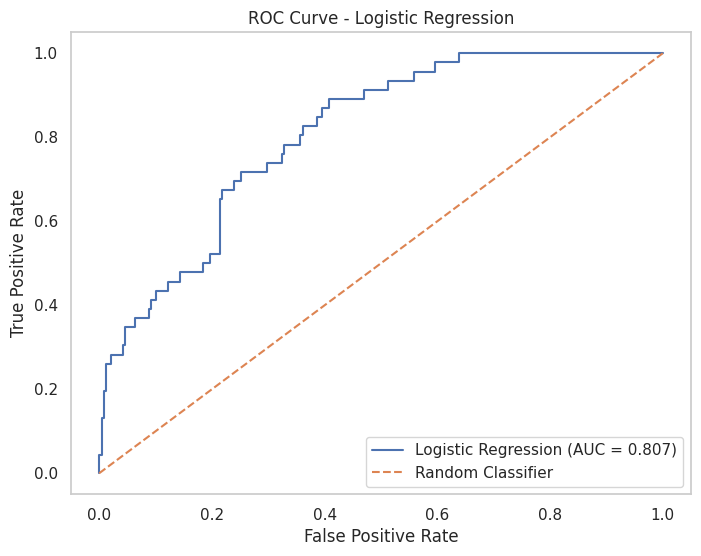

In [ ]:
fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)

plt.figure(figsize=(8, 6))

plt.plot(fpr, tpr, label=f'Logistic Regression (AUC = {roc_auc:.3f})')
plt.plot([0, 1], [0, 1], linestyle='--', label='Random Classifier')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Logistic Regression')
plt.legend()
plt.grid()
plt.show()

 Interpretation of ROC Curve

The ROC curve evaluates the ability of the Logistic Regression model to distinguish between employees who leave and employees who stay.

The model achieved an ROC-AUC score of **0.8075**.

1. The blue curve represents the performance of the Logistic Regression model at different classification thresholds.
2. The orange diagonal line represents a random classifier with an AUC of 0.5.
3. The ROC curve remains above the diagonal line, indicating that the model performs better than random classification.
4. An AUC score of 0.8075 indicates good discriminatory ability between the two employee classes.

**Conclusion:**

The Logistic Regression model demonstrates good ability to distinguish between employees who leave and those who stay. However, further improvements may be required to achieve better precision and overall classification performance.

 6.11 Feature Importance and Coefficient Analysis

This section examines the coefficients learned by the Logistic Regression model to understand how different employee attributes influence its attrition predictions.

Positive coefficients indicate an increase in the predicted odds of attrition, whereas negative coefficients indicate a decrease.

Odds ratios are calculated by exponentiating the coefficients to make their interpretation easier.

This analysis helps identify employee characteristics associated with higher or lower predicted attrition risk.

In [ ]:
feature_names = logistic_model.named_steps['preprocessor'].get_feature_names_out()

coefficients = logistic_model.named_steps['classifier'].coef_[0]

coefficient_df = pd.DataFrame({
    'Feature': feature_names,
    'Coefficient': coefficients
})

coefficient_df['Odds Ratio'] = np.exp(coefficient_df['Coefficient'])

coefficient_df['Absolute Coefficient'] = coefficient_df['Coefficient'].abs()

coefficient_df = coefficient_df.sort_values(
    by='Absolute Coefficient',
    ascending=False
).reset_index(drop=True)

display(coefficient_df.head(15))

,Feature,Coefficient,Odds Ratio,Absolute Coefficient
0,cat__JobRole_Research Director,-1.432586,0.238691,1.432586
1,cat__JobRole_Sales Representative,1.152292,3.165438,1.152292
2,cat__BusinessTravel_Travel_Frequently,0.988406,2.686947,0.988406
3,cat__OverTime_No,-0.987460,0.372522,0.987460
4,cat__OverTime_Yes,0.964621,2.623793,0.964621
5,cat__JobRole_Laboratory Technician,0.854186,2.349462,0.854186
6,cat__EducationField_Technical Degree,0.813121,2.254935,0.813121
7,num__YearsAtCompany,0.766617,2.152473,0.766617
8,cat__BusinessTravel_TravelRarely,-0.688126,0.502517,0.688126
9,cat__JobRole_Human Resources,0.637732,1.892185,0.637732


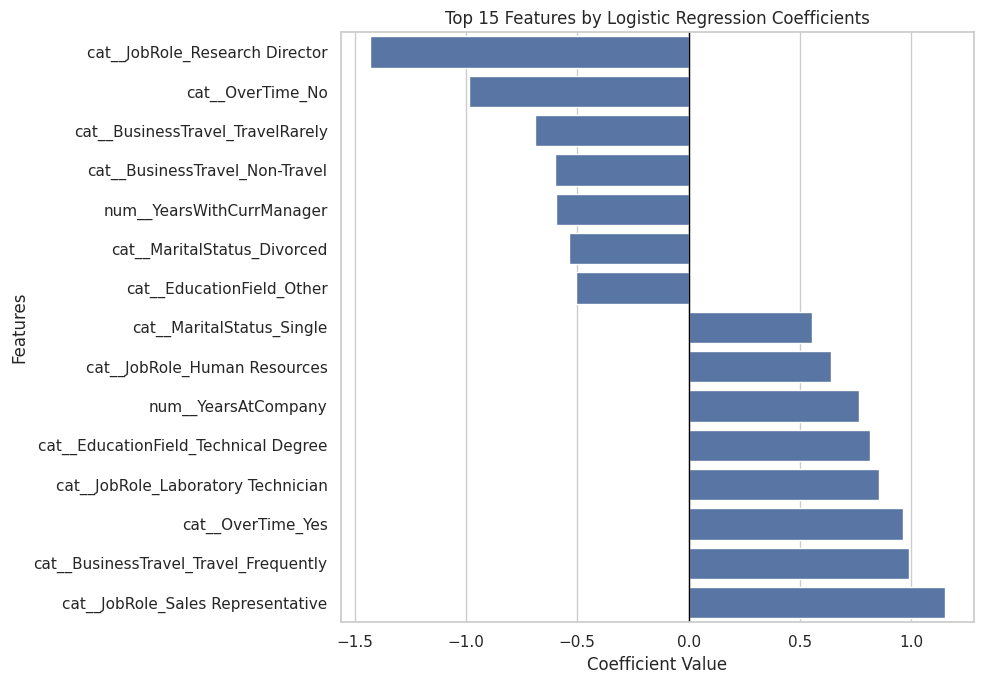

In [ ]:
top_features = coefficient_df.head(15).sort_values(
    by='Coefficient'
)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=top_features,
    x='Coefficient',
    y='Feature'
)

plt.axvline(0, color='black', linewidth=1)

plt.title('Top 15 Features by Logistic Regression Coefficients')
plt.xlabel('Coefficient Value')
plt.ylabel('Features')

plt.tight_layout()
plt.show()

Interpretation of Logistic Regression Coefficients

The coefficient visualization highlights the features that have the strongest positive and negative relationships with the model's predicted employee attrition.

- **Sales Representative** has the strongest positive coefficient among the displayed features.
- **Frequent business travel** and **OverTime = Yes** are positively associated with predicted attrition.
- **Research Director** has the strongest negative coefficient.
- **OverTime = No** and **YearsWithCurrManager** have negative coefficients, indicating lower predicted attrition odds in this fitted model.

These findings help identify employee characteristics that the model considers useful when predicting attrition. However, coefficient values indicate associations within the fitted model and should not be interpreted as causal relationships.

 Overall Conclusion

A Logistic Regression model was developed to predict employee attrition using employee demographics, job-related characteristics, satisfaction levels, and work-related factors.

The model achieved the following performance:

| Evaluation Metric | Score |
|---|---:|
| Accuracy | 75.00% |
| Precision | 35.96% |
| Recall | 69.57% |
| F1-Score | 47.41% |
| ROC-AUC | 80.75% |

The model correctly identified 32 out of 46 employees who actually left the organization. Its recall of 69.57% indicates that it detected a substantial proportion of employees who left, although it also produced false-positive predictions.

The ROC-AUC score of 80.75% indicates good ability to distinguish between employees who left and those who stayed.

**Limitations:**
- The model produced a relatively high number of false positives.
- Logistic Regression assumes a linear relationship between the input features and the log-odds of the outcome.
- The model identifies statistical patterns and does not establish causal relationships.

**Final Conclusion:** Logistic Regression provides a useful baseline for employee attrition prediction. Its results can help identify potential attrition patterns and support further investigation by HR teams.

**7.Business Insights and Recommendations**

The objective of this section is to convert the findings from Exploratory Data Analysis, Statistical Analysis, and Logistic Regression into meaningful business insights.

By identifying factors associated with employee attrition, organizations can better understand employee turnover patterns and develop strategies to improve employee retention.

The analysis focuses on identifying important attrition patterns, understanding their potential business implications, and recommending data-driven actions for HR management.

### Insight 1: Overtime and Employee Attrition

The analysis revealed a strong association between overtime and employee attrition. Employees working overtime had an attrition rate of 30.86%, compared with 10.29% among employees not working overtime.

The Chi-square test showed a statistically significant association (p-value = 4.36 × 10⁻²¹), with a Cramér's V of 0.2504, the highest among the categorical factors examined.

**Business Implication:** Employees working overtime may experience increased workload pressure, fatigue, and difficulty maintaining work-life balance, potentially contributing to employee turnover.

**Recommendation:** HR management should monitor overtime patterns, review workload distribution, encourage work-life balance, and collect employee feedback to identify potential workload-related issues.

**Key Takeaway:** Overtime is an important factor to investigate when developing employee retention strategies.

### Insight 2: Job Satisfaction and Employee Attrition

The analysis indicates an association between job satisfaction and employee attrition. Employees with the lowest job satisfaction (Level 1) had an attrition rate of 22.55%, whereas employees with the highest satisfaction (Level 4) had an attrition rate of 11.36%.

The Chi-square test confirmed a statistically significant association (p-value = 0.001197), with a Cramér's V of 0.1059, indicating a weak association.

**Business Implication:** Lower job satisfaction may be an important indicator of employee turnover risk. Employees who are dissatisfied with their roles may be more likely to leave the organization.

**Recommendation:** Organizations should conduct regular satisfaction surveys, improve employee recognition programs, provide career growth opportunities, and encourage regular communication between employees and managers.

**Key Takeaway:** Improving employee job satisfaction may support better employee retention.

### Insight 3: Work-Life Balance and Employee Attrition

The analysis revealed an association between work-life balance and employee attrition. Employees with the lowest work-life balance (Level 1) had the highest attrition rate of 32.05%, compared with 14.34% among employees at Level 3.

The Chi-square test confirmed a statistically significant association (p-value = 0.0007585), with a Cramér's V of 0.1091, indicating a weak association.

**Business Implication:** Poor work-life balance may contribute to employee dissatisfaction and increased turnover risk. However, the relationship is not perfectly linear across all satisfaction levels.

**Recommendation:** Organizations should monitor employee workloads, encourage employees to use their leave, consider flexible working arrangements, and conduct regular surveys to identify work-life balance concerns.

**Key Takeaway:** Maintaining a healthy work-life balance is an important consideration in employee retention strategies.

### Insight 4: Department-wise Employee Attrition

The department-wise analysis revealed differences in employee attrition rates. The Sales department recorded the highest attrition rate at approximately 20.5%, followed by Human Resources at 19.2%. Research & Development recorded the lowest rate at approximately 13.8%.

The Chi-square test indicated a statistically significant association between department and attrition (p-value = 0.0067). However, the Cramér's V of 0.0879 indicates a weak association.

**Business Implication:** The Sales and Human Resources departments may require additional attention from HR management. Workload, performance expectations, incentives, and employee satisfaction could be investigated to understand department-specific turnover patterns.

**Recommendation:** Organizations should review department-specific working conditions, evaluate performance targets and incentive structures, and conduct employee feedback surveys to identify possible reasons for higher attrition.

**Key Takeaway:** Department-wise analysis can help HR teams develop targeted employee retention strategies.

### Insight 5: Job Role and Employee Attrition

The job-role analysis revealed considerable differences in employee attrition rates across roles. Sales Representatives recorded the highest attrition rate at approximately 39%, followed by Laboratory Technicians at 24% and Human Resources employees at 23%.

In comparison, Research Directors and Managers recorded relatively low attrition rates of approximately 2% and 4%, respectively.

**Business Implication:** Certain job roles may face challenges related to workload, compensation, career growth, or job expectations. Sales Representatives and Laboratory Technicians may require further investigation by HR management.

**Recommendation:** Organizations should review role-specific compensation, workload distribution, career development opportunities, and employee feedback. Exit interviews can also help identify the reasons behind higher turnover in specific roles.

**Key Takeaway:** Job-role analysis helps HR identify employee groups that may benefit from targeted retention strategies.

### Insight 6: Employee Tenure and Employee Attrition

The tenure analysis revealed that employees with 0–2 years of experience at the organization had the highest attrition rate of approximately 30%. Attrition rates were comparatively lower among employees with longer tenure, reaching approximately 6% for employees with 11–20 years at the company.

A slight increase was observed among employees with more than 20 years of tenure.

**Business Implication:** The initial years of employment may represent a critical period for employee retention. New employees may experience difficulties adapting to their roles, responsibilities, or organizational environment.

**Recommendation:** Organizations should implement structured onboarding programs, assign mentors to new employees, conduct regular feedback sessions, and provide training and career development opportunities.

**Key Takeaway:** Strengthening employee engagement and support during the first two years may help improve employee retention.

### Insight 7: Consolidated Statistical and Predictive Model Findings

The combined findings from statistical analysis, correlation analysis, and Logistic Regression provide a broader understanding of employee attrition.

**Statistical Analysis:**
- Overtime showed the strongest association with employee attrition among the categorical factors examined, with a Cramér's V of 0.2504.
- Job Satisfaction, Environment Satisfaction, Work-Life Balance, and Department also showed statistically significant associations with attrition.
- These associations were relatively weak except for the comparatively stronger relationship observed with overtime.

**Correlation Analysis:**
- Total Working Years, Monthly Income, Years in Current Role, and Years with Current Manager showed negative correlations with attrition.
- However, the correlation values were relatively weak, indicating that no single numerical feature explains employee attrition.

**Predictive Model:**
- Logistic Regression achieved an accuracy of 75% and a ROC-AUC score of 80.75%.
- The model achieved a recall of 69.57%, identifying 32 out of 46 actual attrition cases.
- Its relatively low precision of 35.96% indicates that further model improvement may be useful.

**Overall Business Implication:**

Employee attrition is associated with multiple workplace and employee-related factors. Overtime, job satisfaction, work-life balance, department, and employee tenure are useful areas for HR teams to investigate.

The predictive model can serve as an additional decision-support tool to help identify employees who may be at risk of leaving. However, predictions should be reviewed alongside employee feedback and other organizational information rather than used as the sole basis for HR decisions.

**Key Takeaway:** Combining statistical analysis with predictive modelling provides a more comprehensive approach to understanding employee attrition and supporting data-driven HR decisions.

**8.Overall HR Recommendations**

Based on the findings from Exploratory Data Analysis, Statistical Analysis, and Logistic Regression, the following recommendations can help organizations develop effective employee retention strategies.

**1. Monitor Employee Overtime**

Organizations should regularly monitor overtime patterns and distribute workloads fairly to reduce excessive work pressure.

**2. Improve Employee Job Satisfaction**

HR teams should introduce employee recognition programs, career development opportunities, and regular feedback sessions.

**3. Promote Work-Life Balance**

Organizations should encourage flexible working arrangements where possible, monitor workloads, and promote healthy work-life practices.

**4. Implement Department-Specific Retention Strategies**

Departments with relatively higher attrition rates should be investigated to understand their specific employee retention challenges.

**5. Focus on High-Attrition Job Roles**

HR management should review compensation, incentives, working conditions, and career progression opportunities for roles with higher attrition rates.

**6. Strengthen Employee Onboarding**

Structured onboarding, mentorship programs, and regular feedback during the initial employment period can help new employees adapt to the organization.

**7. Use Predictive Analytics for Employee Retention**

Predictive models such as Logistic Regression can help identify potential attrition patterns. HR teams can use these predictions to guide further investigation and provide appropriate employee support.

### Overall Recommendation

Organizations should adopt a proactive, data-driven approach to employee retention by continuously monitoring workforce trends, understanding employee concerns, and implementing targeted retention strategies.

**9.Final Project Conclusion**

This project focused on analyzing employee attrition using data analytics, statistical techniques, and machine learning.

The HR dataset was cleaned and processed to prepare it for analysis. Exploratory Data Analysis was performed to understand employee demographics, job characteristics, satisfaction levels, and attrition patterns.

Statistical techniques, including correlation analysis and Chi-square tests, were used to investigate relationships between employee-related factors and attrition. The findings indicated that overtime had the strongest association with attrition among the categorical factors examined.

A Logistic Regression model was developed to predict employee attrition. The model achieved 75% accuracy, 69.57% recall, and a ROC-AUC score of 80.75%. These results demonstrate its potential as a baseline predictive model, although its precision indicates that further improvement is possible.

The analysis highlighted important areas for HR management to investigate, including overtime, employee satisfaction, work-life balance, department-specific attrition, job roles, and employee tenure.

Overall, this project demonstrates how data analytics and predictive modelling can help organizations understand employee turnover patterns, identify potential retention challenges, and make more informed HR decisions.

**Future Scope:**

- Experiment with advanced classification algorithms such as Random Forest and XGBoost.
- Apply hyperparameter tuning to improve predictive performance.
- Explore additional employee engagement and performance indicators.
- Develop an interactive dashboard to monitor attrition trends.
- Integrate predictive analytics into an HR decision-support system.